# Dados sobre MEI's em 2022 - Fonte IBGE

## Respondi essas perguntas:

#### Quantidade de MEI's por Região e Estados ?

#### Quantidade de Empregados por MEI's ?

#### Qual é a Inadimplência de MEI's por estados ?

#### Quais setores os MEI's estão mais inseridos ?

#### Qual o tempo de vida médio dos MEI's ?

In [3]:
pip install python-bcb geobr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 69.5 MB/s eta 0:00:00
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import geobr
from bcb import sgs

plt.style.use("dark_background")

In [5]:
dados = pd.read_excel("/content/sample_data/MEIs_IBGE_tabela9590_limpo.xlsx", sheet_name="Dados")

dados

,Ano referência,Nível geográfico,Região,UF,Local,Cód. CNAE,Atividade (CNAE 2.0),Nível CNAE,Grupamento pai,Ano de filiação,Tempo de abertura,Com empregado,Atua na residência,Qtd. MEIs,% MEIs (total geral),Qtd. empregados,% empregados (total geral),Valor inibido (X),Linha sem dupla contagem
0,2022,Brasil,—,—,Brasil,A,"Agricultura, pecuária, produção florestal, pes...",Seção,—,2022,Até 3 anos,Sim,Sim,32,0.0000,32.0,0.0002,Não,Não
1,2022,Brasil,—,—,Brasil,A,"Agricultura, pecuária, produção florestal, pes...",Seção,—,2021,Até 3 anos,Sim,Sim,46,0.0000,46.0,0.0003,Não,Não
2,2022,Brasil,—,—,Brasil,A,"Agricultura, pecuária, produção florestal, pes...",Seção,—,2020,Até 3 anos,Sim,Sim,23,0.0000,23.0,0.0002,Não,Não
3,2022,Brasil,—,—,Brasil,B–E,Indústria geral,Grupamento,—,2022,Até 3 anos,Sim,Sim,426,0.0000,426.0,0.0032,Não,Não
4,2022,Brasil,—,—,Brasil,B–E,Indústria geral,Grupamento,—,2021,Até 3 anos,Sim,Sim,720,0.0000,720.0,0.0054,Não,Não
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10291,2022,UF,Centro-Oeste,DF,Distrito Federal,T,Serviços domésticos,Seção,R–U,2021,Até 3 anos,Não,Não,470,0.0019,0.0,0.0000,Não,Sim
10292,2022,UF,Centro-Oeste,DF,Distrito Federal,T,Serviços domésticos,Seção,R–U,2020,Até 3 anos,Não,Não,319,0.0013,0.0,0.0000,Não,Sim
10293,2022,UF,Centro-Oeste,DF,Distrito Federal,U,Organismos internacionais e outras instituiçõe...,Seção,R–U,2022,Até 3 anos,Não,Não,0,0.0000,0.0,0.0000,Não,Sim
10294,2022,UF,Centro-Oeste,DF,Distrito Federal,U,Organismos internacionais e outras instituiçõe...,Seção,R–U,2021,Até 3 anos,Não,Não,0,0.0000,0.0,0.0000,Não,Sim


In [6]:
dados.columns

Index(['Ano referência', 'Nível geográfico', 'Região', 'UF', 'Local',
       'Cód. CNAE', 'Atividade (CNAE 2.0)', 'Nível CNAE', 'Grupamento pai',
       'Ano de filiação', 'Tempo de abertura', 'Com empregado',
       'Atua na residência', 'Qtd. MEIs', '% MEIs (total geral)',
       'Qtd. empregados', '% empregados (total geral)', 'Valor inibido (X)',
       'Linha sem dupla contagem'],
      dtype='object')

regions_2020_simplified.parquet: 100%|██████████| 979k/979k [00:00<00:00, 38.6MB/s]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

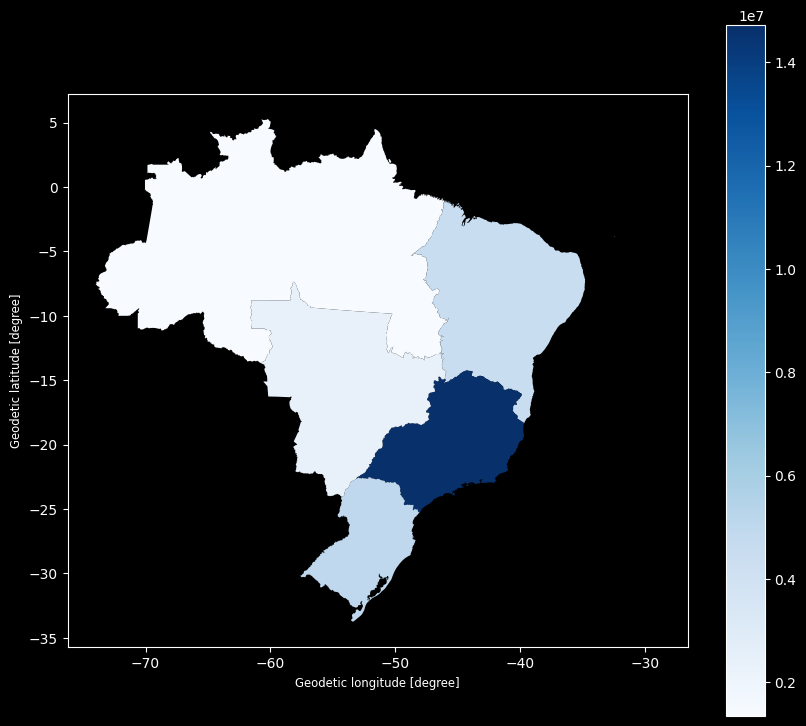

In [7]:
regioes = dados.groupby("Região")["Qtd. MEIs"].sum().reset_index()
regioes = regioes[regioes["Região"] != "--"]

mapa = geobr.read_region(year=2020).merge(
    regioes, left_on="name_region", right_on="Região", how="left"
)

mapa.plot(column="Qtd. MEIs", cmap="Blues", legend=True, figsize=(10, 10))

In [8]:
dados["Tempo de abertura"].value_counts()

,count
Tempo de abertura,
Até 3 anos,10296


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

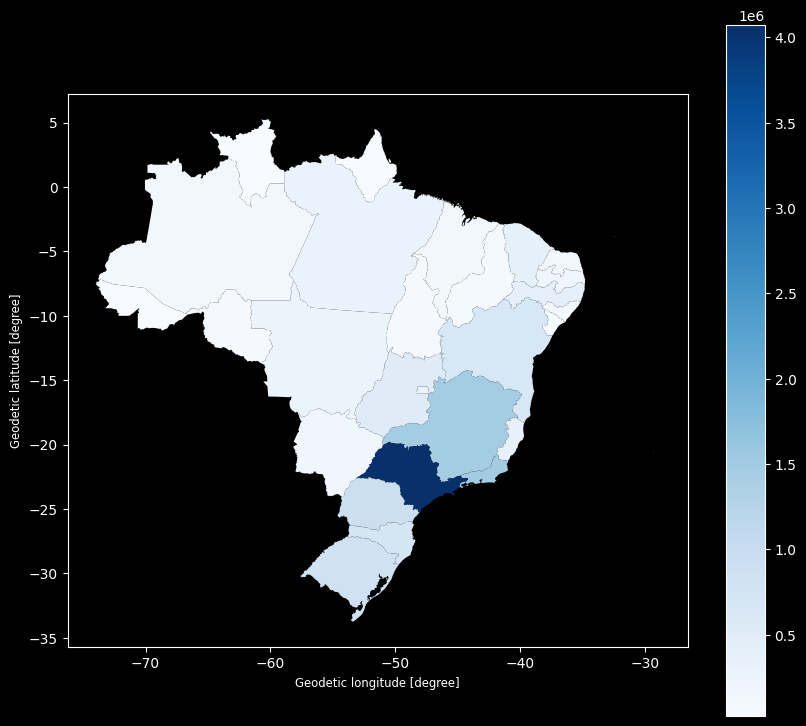

In [10]:
ufs = dados.groupby("UF")["Qtd. MEIs"].sum().reset_index()

ufs = ufs[ufs["UF"] != "—"]

mapa = geobr.read_state(year=2020).merge(
    ufs, left_on="abbrev_state", right_on="UF", how="left"
)

mapa.plot(column="Qtd. MEIs", cmap="Blues", legend=True, figsize=(10, 10))


In [11]:
meis_servico = dados.groupby("Atividade (CNAE 2.0)")["Qtd. MEIs"].sum().reset_index().sort_values("Qtd. MEIs",ascending=False).head(10)

meis_servico

,Atividade (CNAE 2.0),Qtd. MEIs
22,Serviços,11579841
9,Comércio; reparação de veículos automotores e ...,5516151
17,"Informação, comunicação e atividades financeir...",3111609
20,Outros serviços,2700609
3,Alojamento e alimentação,2389209
24,"Transporte, armazenagem e correio",2161854
19,Outras atividades de serviços,2115933
13,Indústria geral,2115321
14,Indústrias de transformação,2042178
10,Construção,1813986


In [31]:
qtd_uf = ufs.sort_values('Qtd. MEIs', ascending=False)

qtd_uf

,UF,Qtd. MEIs
25,SP,4074144
18,RJ,1482897
10,MG,1478757
17,PR,923556
22,RS,845571
23,SC,717527
4,BA,666695
8,GO,500593
15,PE,405821
5,CE,375695


In [21]:
empregados_meis = dados.groupby(["UF", "Região"])["Qtd. empregados"].sum().reset_index().sort_values("Qtd. empregados",ascending=False)

empregados_meis = empregados_meis[empregados_meis["UF"] != "—" ]

empregados_meis.head(10)

,UF,Região,Qtd. empregados
25,SP,Sudeste,15269.0
10,MG,Sudeste,13548.0
17,PR,Sul,5454.0
23,SC,Sul,5009.0
8,GO,Centro-Oeste,4527.0
22,RS,Sul,4272.0
4,BA,Nordeste,3699.0
18,RJ,Sudeste,3580.0
15,PE,Nordeste,2980.0
7,ES,Sudeste,2184.0


In [22]:
dados["Atua na residência"].value_counts()

,count
Atua na residência,
Sim,5148
Não,5148


### Dados de Inadimplência de MEI'S por estado

In [53]:
codigos_mei = {
    "SP": 27105,
    "RJ": 27099,
    "MG": 27093,
    "PR": 27096,
    "RS": 27101,
    "SC": 27104,
    "BA": 26749,
    "GO": 27089,
    "PE": 27097,
    "CE": 27086,
}

dados_mei = sgs.get(codigos_mei, start="2016-03-01")

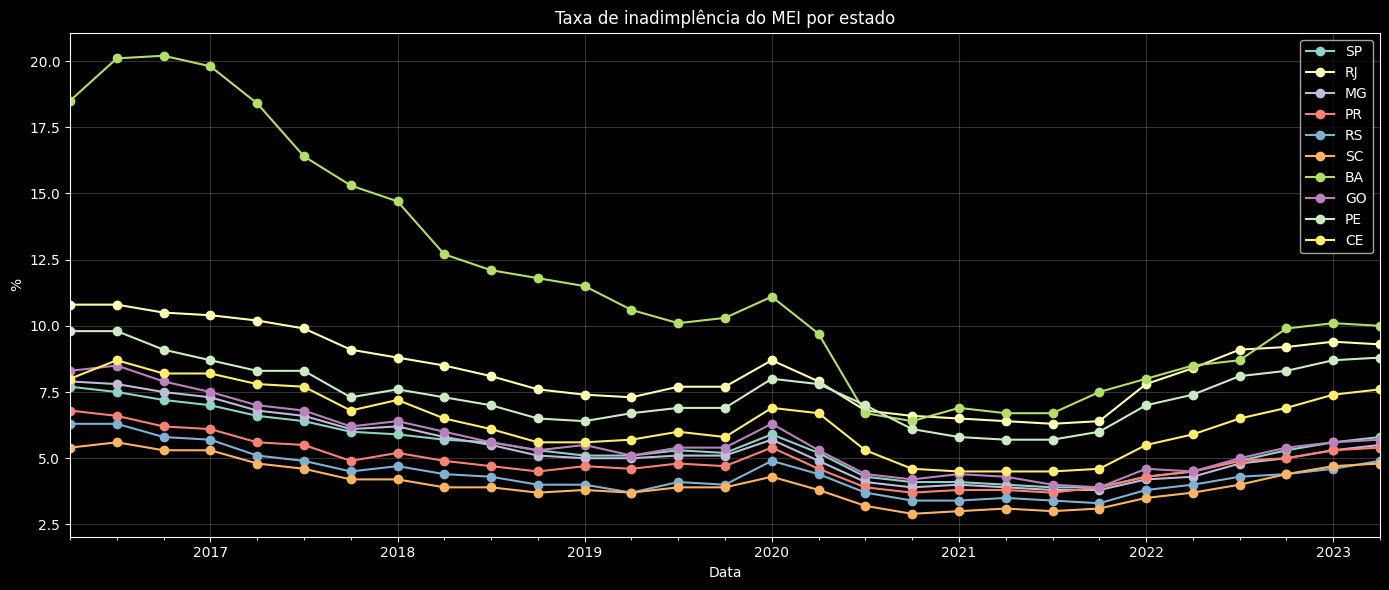

In [54]:
ax = dados_mei.plot(figsize=(14, 6), marker="o", linewidth=1.5)
ax.set_title("Taxa de inadimplência do MEI por estado")
ax.set_ylabel("%")
ax.set_xlabel("Data")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [27]:
dados_mei = dados_mei.reset_index()

dados_mei["Ano"] = dados_mei["Date"].dt.year

inadimplecia_2022 = dados_mei[dados_mei["Ano"] == 2022]

ina

,Date,SP,RJ,MG,PR,RS,SC,BA,GO,PE,CE,Ano
23,2022-01-01,4.3,7.8,4.2,4.3,3.8,3.5,8.0,4.6,7.0,5.5,2022
24,2022-04-01,4.5,8.4,4.3,4.5,4.0,3.7,8.5,4.5,7.4,5.9,2022
25,2022-07-01,4.9,9.1,4.8,4.9,4.3,4.0,8.7,5.0,8.1,6.5,2022
26,2022-10-01,5.3,9.2,5.0,5.0,4.4,4.4,9.9,5.4,8.3,6.9,2022


In [34]:
inadimplecia_2022 = inadimplecia_2022.melt(
    id_vars=["Date", "Ano"],
    var_name="UF",
    value_name="Taxa_Inadimplencia"
)

inadimplecia_2022 = inadimplecia_2022.groupby(["Ano","UF"])["Taxa_Inadimplencia"].mean().reset_index()

inadimplecia_2022

,Ano,UF,Taxa_Inadimplencia
0,2022,BA,8.775
1,2022,CE,6.200
2,2022,GO,4.875
3,2022,MG,4.575
4,2022,PE,7.700
5,2022,PR,4.675
6,2022,RJ,8.625
7,2022,RS,4.125
8,2022,SC,3.900
9,2022,SP,4.750


In [42]:
inadimplencia_uf = inadimplecia_2022.merge(qtd_uf, on="UF", how='left')

inadimplencia_uf["MEIs_Inadimplentes"]  = inadimplencia_uf["Taxa_Inadimplencia"] / (100 * inadimplencia_uf["Qtd. MEIs"])

inadimplencia_uf

,Ano,UF,Taxa_Inadimplencia,Qtd. MEIs,MEIs_Inadimplentes
0,2022,BA,8.775,666695,1.000000e-07
1,2022,CE,6.200,375695,2.000000e-07
2,2022,GO,4.875,500593,1.000000e-07
3,2022,MG,4.575,1478757,0.000000e+00
4,2022,PE,7.700,405821,2.000000e-07
5,2022,PR,4.675,923556,1.000000e-07
6,2022,RJ,8.625,1482897,1.000000e-07
7,2022,RS,4.125,845571,0.000000e+00
8,2022,SC,3.900,717527,1.000000e-07
9,2022,SP,4.750,4074144,0.000000e+00


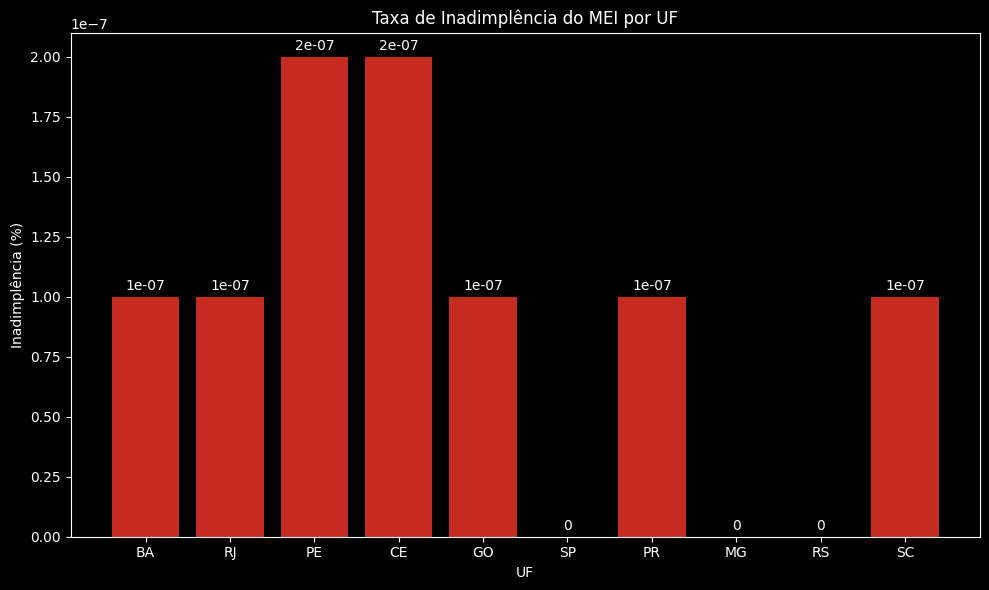

In [48]:
inadimplencia_uf = inadimplencia_uf.sort_values("Taxa_Inadimplencia", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(inadimplencia_uf["UF"], inadimplencia_uf["MEIs_Inadimplentes"], color="#C52B21")

ax.bar_label(barras, padding=3)
ax.set_title("Taxa de Inadimplência do MEI por UF")
ax.set_xlabel("UF")
ax.set_ylabel("Inadimplência (%)")


plt.tight_layout()
plt.show()